In [ ]:
import pandas as pd
from collections import Counter
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from IPython.display import display

import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [ ]:
# Leer datos desde un archivo CSV
df = pd.read_csv('https://raw.githubusercontent.com/omarmendoza564/datos/refs/heads/main/datos/transactions.csv', header=None)
df

,0,1,2,3,4,5,6
0,Pan,Leche,Mantequilla,Vino,Aceite,NaN,NaN
1,Pan,Pañal,Cerveza,Huevos,NaN,NaN,NaN
2,Pan,Pañal,Cerveza,Huevos,NaN,NaN,NaN
3,Leche,Pañal,Cerveza,Coca-Cola,NaN,NaN,NaN
4,Pan,Leche,Pañal,Coca-Cola,Vino,Aceite,Mantequilla
...,...,...,...,...,...,...,...
95,Pan,Leche,Pañal,Coca-Cola,Vino,Aceite,Mantequilla
96,Leche,Pañal,Cerveza,Coca-Cola,Aceite,NaN,NaN
97,Leche,Pañal,Cerveza,Coca-Cola,Vino,Aceite,Mantequilla
98,Pan,Leche,Pañal,Coca-Cola,Mantequilla,NaN,NaN


In [ ]:
# Preparar las transacciones sin convertir valores faltantes en cadenas.
transactions = [fila.dropna().astype(str).tolist() for _, fila in df.iterrows()]
transactions = [t for t in transactions if t]
print(f"Número de transacciones: {len(transactions)}")
transactions[:5]

Número de transacciones: 100


[['Pan', 'Leche', 'Mantequilla', 'Vino', 'Aceite'],
 ['Pan', 'Pañal', 'Cerveza', 'Huevos'],
 ['Pan', 'Pañal', 'Cerveza', 'Huevos'],
 ['Leche', 'Pañal', 'Cerveza', 'Coca-Cola'],
 ['Pan', 'Leche', 'Pañal', 'Coca-Cola', 'Vino', 'Aceite', 'Mantequilla']]

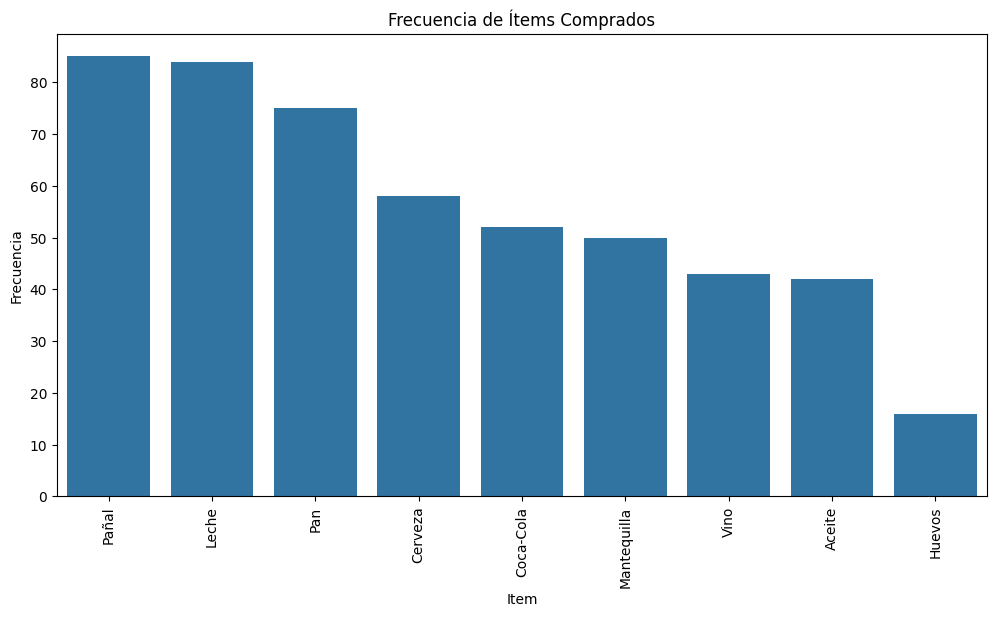

In [ ]:
#Analizar la frecuencia de cada ítem vendido en las transacciones
from collections import Counter
item_counts = Counter([item for transaction in transactions for item in transaction])
item_df = pd.DataFrame(item_counts.items(), columns=['Item', 'Frecuencia']).sort_values(by='Frecuencia', ascending=False)

plt.figure(figsize=(12,6))
sns.barplot(x='Item', y='Frecuencia', data=item_df)
plt.xticks(rotation=90)
plt.title('Frecuencia de Ítems Comprados')
plt.show()


In [ ]:
# Contar el número de ítems en cada transacción
num_items_per_transaction = [len(transaction) for transaction in transactions]
# Convertir la lista en una Serie de pandas para fácil manipulación
num_items_series = pd.Series(num_items_per_transaction)
display(num_items_series.describe(percentiles=[.25, .5, .75, .9]))
# Interpretar el percentil 90 según el valor que muestre el conjunto de datos.
#print(num_items_series.quantile([0.25, 0.5, 0.75, 0.9]))

,0
count,100.00000
mean,5.05000
std,1.37345
min,2.00000
25%,4.00000
50%,5.00000
75%,6.00000
90%,7.00000
max,7.00000


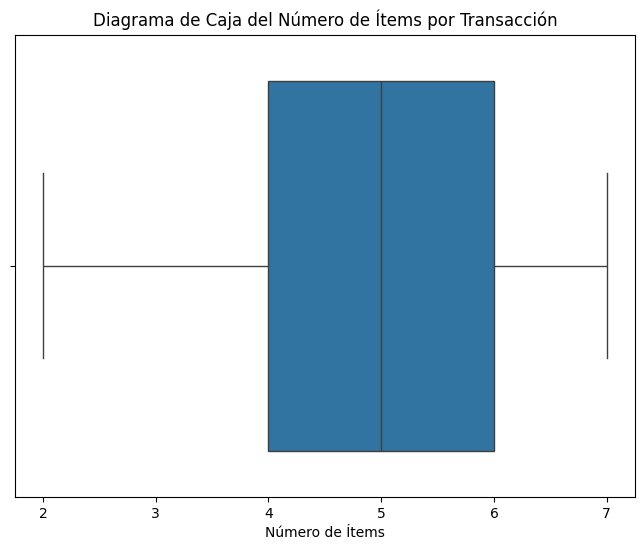

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(x=num_items_per_transaction)
plt.title('Diagrama de Caja del Número de Ítems por Transacción')
plt.xlabel('Número de Ítems')
plt.show()

# TRANSFORMACION DE LOS DATOS

In [ ]:
# Entrenar el objeto TransactionEncoder y transformar los datos
encoder = TransactionEncoder()
transactions_encoded = encoder.fit(transactions).transform(transactions)
transactions_encoded = pd.DataFrame(transactions_encoded, columns=encoder.columns_)
transactions_encoded.head(3)

,Aceite,Cerveza,Coca-Cola,Huevos,Leche,Mantequilla,Pan,Pañal,Vino
0,True,False,False,False,True,True,True,False,True
1,False,True,False,True,False,False,True,True,False
2,False,True,False,True,False,False,True,True,False


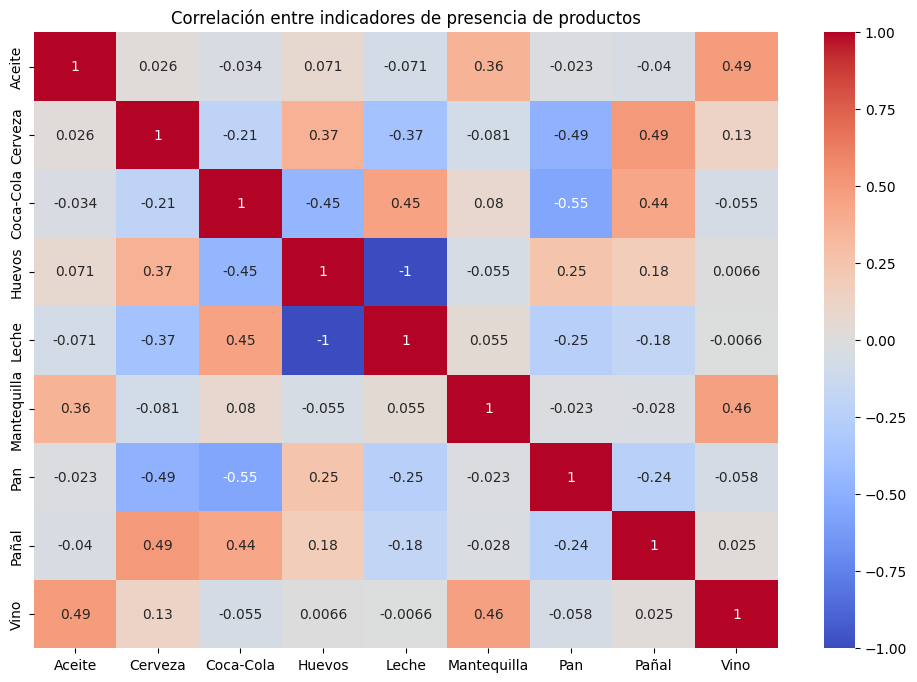

In [ ]:
# La correlación de Pearson entre indicadores binarios es exploratoria;
# no equivale a soporte, confianza ni lift de una regla.
corr = transactions_encoded.astype(int).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación entre indicadores de presencia de productos')
plt.show()

In [ ]:
# Porcentaje de transacciones en las que aparece cada producto
transactions_encoded.mean(axis = 0).sort_values(ascending = False)

,0
Pañal,0.85
Leche,0.84
Pan,0.75
Cerveza,0.58
Coca-Cola,0.52
Mantequilla,0.50
Vino,0.43
Aceite,0.42
Huevos,0.16


## IDENTIFICAR LOS ITEM SET FRECUENTES CON APRIORI

In [ ]:
min_frecuencia = 30
soporte = min_frecuencia / len(transactions)
print(f"Soporte mínimo: {soporte:.2%} ({min_frecuencia} de {len(transactions)} transacciones)")
itemsets = apriori(transactions_encoded, min_support=soporte, use_colnames=True)
display(itemsets.sort_values(by='support', ascending=False))

Soporte mínimo: 30.00% (30 de 100 transacciones)


,support,itemsets
6,0.85,(Pañal)
3,0.84,(Leche)
5,0.75,(Pan)
20,0.69,"(Leche, Pañal)"
25,0.60,"(Pan, Pañal)"
19,0.59,"(Leche, Pan)"
1,0.58,(Cerveza)
15,0.58,"(Cerveza, Pañal)"
2,0.52,(Coca-Cola)
30,0.52,"(Leche, Coca-Cola, Pañal)"


In [ ]:
# Top 10 itemsets con mayor soporte
itemsets.sort_values(by='support', ascending=False).head(10)

,support,itemsets
6,0.85,(Pañal)
3,0.84,(Leche)
5,0.75,(Pan)
20,0.69,"(Leche, Pañal)"
25,0.60,"(Pan, Pañal)"
19,0.59,"(Leche, Pan)"
1,0.58,(Cerveza)
15,0.58,"(Cerveza, Pañal)"
2,0.52,(Coca-Cola)
30,0.52,"(Leche, Coca-Cola, Pañal)"


In [ ]:
# Top 10 itemsets con al menos 2 items, ordenados por soporte
itemsets[itemsets["itemsets"].apply(lambda x: len(x) >=2)]\
.sort_values(by="support", ascending=False).head(10)

,support,itemsets
20,0.69,"(Leche, Pañal)"
25,0.60,"(Pan, Pañal)"
19,0.59,"(Leche, Pan)"
15,0.58,"(Cerveza, Pañal)"
30,0.52,"(Leche, Coca-Cola, Pañal)"
16,0.52,"(Leche, Coca-Cola)"
17,0.52,"(Coca-Cola, Pañal)"
33,0.44,"(Leche, Pan, Pañal)"
18,0.43,"(Leche, Mantequilla)"
28,0.42,"(Leche, Cerveza, Pañal)"


In [ ]:
#Itemset que contengan Mantequilla
itemsets[itemsets["itemsets"].apply(lambda x: "Mantequilla" in list(x))]\
.sort_values(by="support", ascending=False)

,support,itemsets
4,0.50,(Mantequilla)
18,0.43,"(Leche, Mantequilla)"
23,0.42,"(Mantequilla, Pañal)"
22,0.37,"(Mantequilla, Pan)"
32,0.35,"(Leche, Mantequilla, Pañal)"
24,0.33,"(Mantequilla, Vino)"
9,0.30,"(Mantequilla, Aceite)"
31,0.30,"(Pan, Leche, Mantequilla)"


In [ ]:
#Buscar intems que contengan Vino y Pañal
i = {"Vino","Pañal"}
itemsets[itemsets["itemsets"].apply(lambda x: set(x).issuperset(i))]\
.sort_values(by="support", ascending=False)

,support,itemsets
27,0.37,"(Vino, Pañal)"
34,0.30,"(Leche, Vino, Pañal)"


## GENERAR LAS REGLAS DE ASOCIACION

In [ ]:
# Generar reglas con confianza mínima de 70 %.
confianza = 0.70
rules = association_rules(itemsets, metric="confidence", min_threshold=confianza)
print(f"Número de reglas generadas: {len(rules)}")
display(rules.sort_values(by='confidence').head(10))

Número de reglas generadas: 38


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
33,(Mantequilla),"(Leche, Pañal)",0.50,0.69,0.35,0.700000,1.014493,1.0,0.0050,1.033333,0.028571,0.416667,0.032258,0.603623
10,(Leche),(Pan),0.84,0.75,0.59,0.702381,0.936508,1.0,-0.0400,0.840000,-0.297619,0.590000,-0.190476,0.744524
19,(Pañal),(Pan),0.85,0.75,0.60,0.705882,0.941176,1.0,-0.0375,0.850000,-0.294118,0.600000,-0.176471,0.752941
4,(Aceite),(Vino),0.42,0.43,0.30,0.714286,1.661130,1.0,0.1194,1.995000,0.686207,0.545455,0.498747,0.705980
1,(Aceite),(Mantequilla),0.42,0.50,0.30,0.714286,1.428571,1.0,0.0900,1.750000,0.517241,0.483871,0.428571,0.657143
20,(Vino),(Pan),0.43,0.75,0.31,0.720930,0.961240,1.0,-0.0125,0.895833,-0.066068,0.356322,-0.116279,0.567132
24,(Cerveza),"(Leche, Pañal)",0.58,0.69,0.42,0.724138,1.049475,1.0,0.0198,1.123750,0.112245,0.494118,0.110122,0.666417
23,"(Cerveza, Pañal)",(Leche),0.58,0.84,0.42,0.724138,0.862069,1.0,-0.0672,0.580000,-0.275862,0.420000,-0.724138,0.612069
5,(Cerveza),(Leche),0.58,0.84,0.42,0.724138,0.862069,1.0,-0.0672,0.580000,-0.275862,0.420000,-0.724138,0.612069
35,"(Pan, Pañal)",(Leche),0.60,0.84,0.44,0.733333,0.873016,1.0,-0.0640,0.600000,-0.266667,0.440000,-0.666667,0.628571


### Ejemplos

- **Mantequilla → {Pañal, Leche}**: soporte del **35 %**, confianza del **70 %** y lift ≈ **1.014493**. La coocurrencia apenas supera lo esperado bajo independencia; no es evidencia de influencia causal.
- **Aceite → Mantequilla**: lift ≈ **1.428571**. La coocurrencia supera la esperada bajo independencia; para valorar su utilidad también deben examinarse soporte y confianza.
- **Cerveza → Leche**: confianza ≈ **72.41 %**, pero lift ≈ **0.862069**. Aunque la confianza supera el umbral, la asociación es negativa respecto a la independencia.

Estas asociaciones pueden orientar hipótesis de promociones o análisis comercial, pero deben interpretarse según el contexto y sin atribuir causalidad.# Generar reglas con confianza mínima de 70 %.
confianza = 0.70
rules = association_rules(itemsets, metric="confidence", min_threshold=confianza)
print(f"Número de reglas generadas: {len(rules)}")
display(rules.sort_values(by='confidence').head(10))

### Análisis detallado de una regla: Coca-Cola → Pañal

Resultados observados en el ejemplo original:

| Métrica | Valor | Interpretación |
|---|---:|---|
| Soporte del antecedente | 52 % | El 52 % de las transacciones contiene Coca-Cola. |
| Soporte del consecuente | 85 % | El 85 % contiene Pañal. |
| Soporte | 52 % | El 52 % contiene ambos productos. |
| Confianza | 100 % | En estos datos, todas las transacciones con Coca-Cola también contienen Pañal. |
| Lift | 1.176471 | Asociación positiva respecto a independencia, **relativamente cercana a 1**. |
| Leverage | 0.0780 | La coocurrencia observada excede en 0.078 la esperada bajo independencia. |
| Conviction | ∞ | No se observaron transacciones con Coca-Cola sin Pañal; no implica causalidad. |

**Interpretación:** La confianza de 100 % debe contrastarse con el soporte del consecuente, que ya es alto (85 %). Por ello, **confianza alta no equivale necesariamente a una asociación fuerte**. La regla describe las transacciones analizadas, no garantiza compras futuras ni demuestra que un producto provoque la compra del otro.

In [ ]:
confianza_exploratoria = 0.01
rules_azar = association_rules(itemsets, metric="confidence", min_threshold=confianza_exploratoria)
print(f"Número de reglas: {len(rules_azar)}")
display(rules_azar.sort_values(by="lift", ascending=True))

Número de reglas: 82


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
12,(Cerveza),(Pan),0.58,0.75,0.33,0.568966,0.758621,1.0,-0.1050,0.580000,-0.431034,0.330000,-0.724138,0.504483
13,(Pan),(Cerveza),0.75,0.58,0.33,0.440000,0.758621,1.0,-0.1050,0.750000,-0.560000,0.330000,-0.333333,0.504483
50,(Pan),"(Cerveza, Pañal)",0.75,0.58,0.33,0.440000,0.758621,1.0,-0.1050,0.750000,-0.560000,0.330000,-0.333333,0.504483
47,"(Cerveza, Pañal)",(Pan),0.58,0.75,0.33,0.568966,0.758621,1.0,-0.1050,0.580000,-0.431034,0.330000,-0.724138,0.504483
74,(Pan),"(Leche, Pañal)",0.75,0.69,0.44,0.586667,0.850242,1.0,-0.0775,0.750000,-0.413333,0.440000,-0.333333,0.612174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53,"(Leche, Pañal)",(Coca-Cola),0.69,0.52,0.52,0.753623,1.449275,1.0,0.1612,1.948235,1.000000,0.753623,0.486715,0.876812
33,(Vino),(Mantequilla),0.43,0.50,0.33,0.767442,1.534884,1.0,0.1150,2.150000,0.611377,0.550000,0.534884,0.713721
32,(Mantequilla),(Vino),0.50,0.43,0.33,0.660000,1.534884,1.0,0.1150,1.676471,0.696970,0.550000,0.403509,0.713721
9,(Aceite),(Vino),0.42,0.43,0.30,0.714286,1.661130,1.0,0.1194,1.995000,0.686207,0.545455,0.498747,0.705980


In [ ]:
#Filtrar reglas con antecedente específico (ej. "Mantequilla")
rules[rules['antecedents'].apply(lambda x: 'Mantequilla' in x)].sort_values(by='confidence', ascending=False)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
9,(Mantequilla),(Leche),0.50,0.84,0.43,0.860000,1.023810,1.0,0.0100,1.142857,0.046512,0.472527,0.125000,0.685952
16,(Mantequilla),(Pañal),0.50,0.85,0.42,0.840000,0.988235,1.0,-0.0050,0.937500,-0.023256,0.451613,-0.066667,0.667059
32,"(Mantequilla, Pañal)",(Leche),0.42,0.84,0.35,0.833333,0.992063,1.0,-0.0028,0.960000,-0.013605,0.384615,-0.041667,0.625000
31,"(Leche, Mantequilla)",(Pañal),0.43,0.85,0.35,0.813953,0.957592,1.0,-0.0155,0.806250,-0.072093,0.376344,-0.240310,0.612859
30,"(Mantequilla, Pan)",(Leche),0.37,0.84,0.30,0.810811,0.965251,1.0,-0.0108,0.845714,-0.054054,0.329670,-0.182432,0.583977
15,(Mantequilla),(Pan),0.50,0.75,0.37,0.740000,0.986667,1.0,-0.0050,0.961538,-0.026316,0.420455,-0.040000,0.616667
33,(Mantequilla),"(Leche, Pañal)",0.50,0.69,0.35,0.700000,1.014493,1.0,0.0050,1.033333,0.028571,0.416667,0.032258,0.603623


In [ ]:
#Filtrar reglas con antecedente específico (ej. "Mantequilla")
rules[rules['consequents'].apply(lambda x: 'Mantequilla' in x)].sort_values(by='confidence', ascending=False)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
17,(Vino),(Mantequilla),0.43,0.5,0.33,0.767442,1.534884,1.0,0.115,2.15,0.611377,0.550000,0.534884,0.713721
1,(Aceite),(Mantequilla),0.42,0.5,0.30,0.714286,1.428571,1.0,0.090,1.75,0.517241,0.483871,0.428571,0.657143


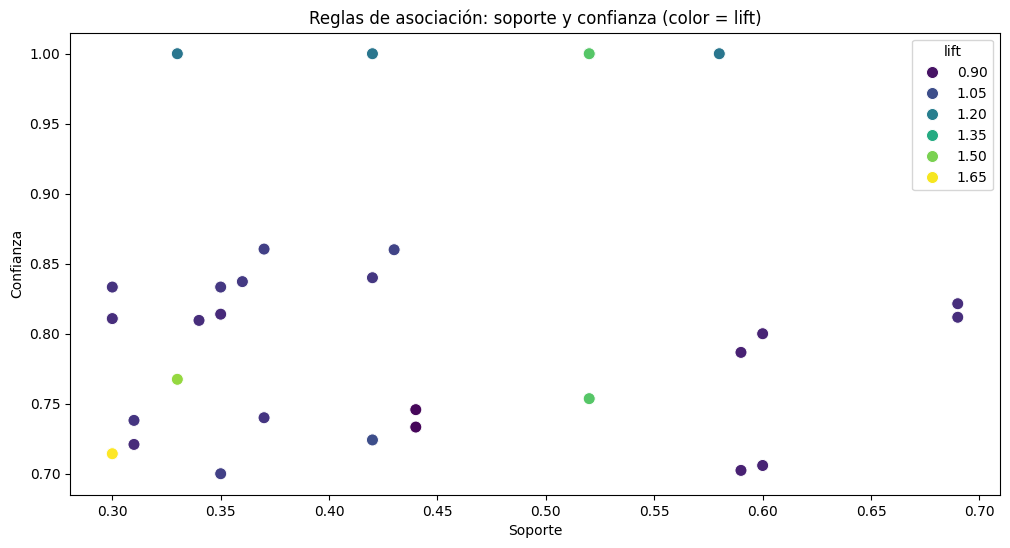

In [ ]:
# Dispersión: soporte frente a confianza de las reglas.
plt.figure(figsize=(12, 6))
sns.scatterplot(data=rules, x='support', y='confidence', hue='lift', palette='viridis', s=75)
plt.xlabel('Soporte')
plt.ylabel('Confianza')
plt.title('Reglas de asociación: soporte y confianza (color = lift)')
plt.show()

### Interpretación: bajo soporte y alta confianza

- **Bajo soporte**: la combinación de antecedente y consecuente aparece en una proporción pequeña de transacciones.
- **Alta confianza**: entre las transacciones que contienen el antecedente, una proporción alta también contiene el consecuente.

Una regla puede tener alta confianza y bajo soporte. Para interpretarla, conviene revisar además el **lift** y el número de transacciones que la respaldan; una confianza alta no garantiza una asociación intensa ni relevancia práctica.



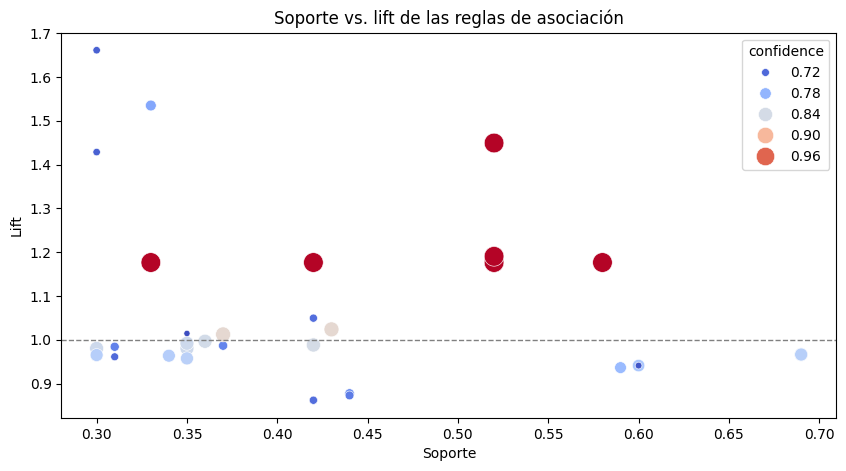

In [ ]:
  # Soporte frente a lift; el color y el tamaño indican confianza.
plt.figure(figsize=(10, 5))
sns.scatterplot(data=rules, x='support', y='lift', hue='confidence',
                palette='coolwarm', size='confidence', sizes=(20, 200))
plt.axhline(1, color='gray', linestyle='--', linewidth=1, label='Lift = 1')
plt.xlabel('Soporte')
plt.ylabel('Lift')
plt.title('Soporte vs. lift de las reglas de asociación')
plt.show()



In [ ]:
# Revisar las reglas con alta confianza
rules[rules['confidence'] >= 0.9][['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values(by='support')

,antecedents,consequents,support,confidence,lift
25,"(Cerveza, Pan)",(Pañal),0.33,1.0,1.176471
22,"(Leche, Cerveza)",(Pañal),0.42,1.0,1.176471
8,(Coca-Cola),(Pañal),0.52,1.0,1.176471
7,(Coca-Cola),(Leche),0.52,1.0,1.190476
28,"(Coca-Cola, Pañal)",(Leche),0.52,1.0,1.190476
26,"(Leche, Coca-Cola)",(Pañal),0.52,1.0,1.176471
29,(Coca-Cola),"(Leche, Pañal)",0.52,1.0,1.449275
6,(Cerveza),(Pañal),0.58,1.0,1.176471


/tmp/ipykernel_1715/3005201128.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


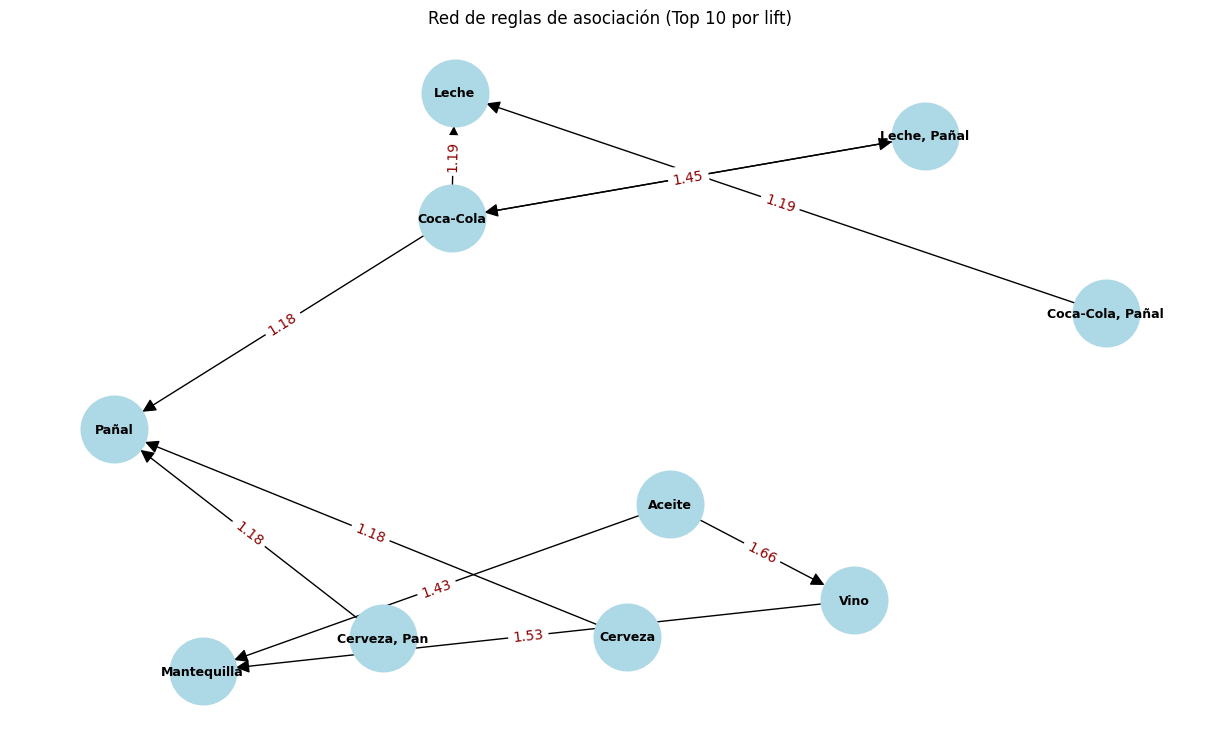

In [ ]:
# Red de reglas de asociación (Top 10 por lift).
# Cada conjunto de ítems se representa como un nodo completo, para no
# descomponer incorrectamente reglas con varios ítems.
G = nx.DiGraph()
top_rules = rules.sort_values(by='lift', ascending=False).head(10)
for _, row in top_rules.iterrows():
    antecedente = ', '.join(sorted(row['antecedents']))
    consecuente = ', '.join(sorted(row['consequents']))
    G.add_edge(antecedente, consecuente, weight=row['lift'])
plt.figure(figsize=(12, 7))
pos = nx.spring_layout(G, k=1, seed=42)
nx.draw(G, pos, with_labels=True, node_size=2300, node_color='lightblue',
        font_size=9, font_weight='bold', arrowsize=20)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos,
    edge_labels={k: f"{v:.2f}" for k, v in labels.items()}, font_color='darkred')
plt.title('Red de reglas de asociación (Top 10 por lift)')
plt.tight_layout()
plt.show()

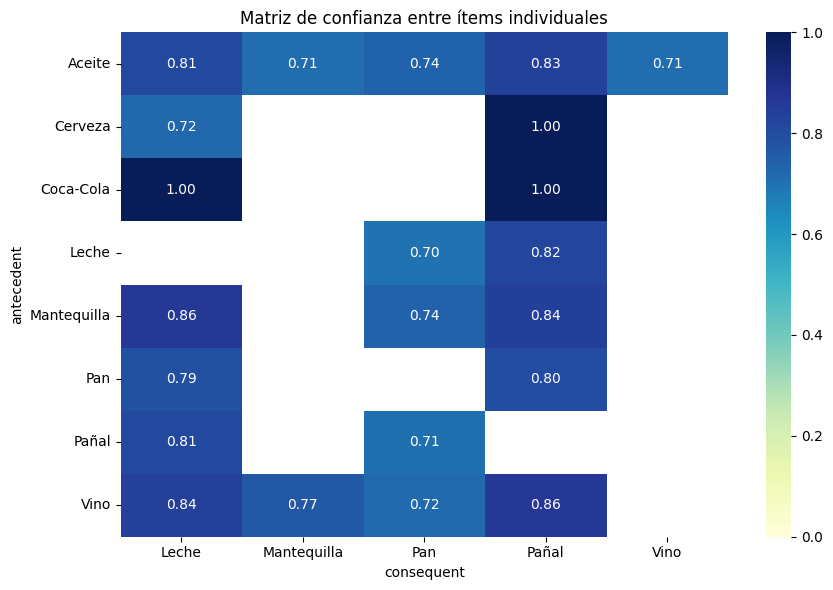

In [ ]:
# Matriz de confianza para reglas con un ítem en cada lado.
pair_rules = rules.loc[
    rules['antecedents'].apply(len).eq(1) & rules['consequents'].apply(len).eq(1)
].copy()
pair_rules['antecedent'] = pair_rules['antecedents'].apply(lambda x: next(iter(x)))
pair_rules['consequent'] = pair_rules['consequents'].apply(lambda x: next(iter(x)))
pivot = pair_rules.pivot(index='antecedent', columns='consequent', values='confidence')
plt.figure(figsize=(9, 6))
sns.heatmap(pivot, annot=True, cmap='YlGnBu', fmt='.2f', vmin=0, vmax=1)
plt.title('Matriz de confianza entre ítems individuales')
plt.tight_layout()
plt.show()